# 55. Crackle: how much, when, and from where on the trajectory

"Crackle" is the impulsive, popping component of rocket and jet noise. It comes from steep shock
fronts in the waveform: pressure rises abruptly and decays slowly, so the waveform and especially its
time derivative are strongly **positively skewed**. Standard measures (4-s windows here):

* **OASPL**: overall sound pressure level, dB re 20 µPa;
* **Sk(p)**: skewness of pressure; crackle has conventionally been associated with Sk(p) ≳ 0.4
  (Ffowcs Williams et al., 1975);
* **Sk(dp/dt)**: skewness of the time derivative, a sharper indicator of shock content (Gee et al.);
* **steep-front rate**: positive excursions of dp/dt above 5× its RMS per second.

Each window's arrival time is mapped to the **source time** at which that sound was emitted (straight
rays, nominal trajectory: `cfg.source_geometry`), so crackle can be related to the vehicle's altitude
and speed. The 24-bit, 500-sps infraBSU channels (B01, B05, B29) are used; B03's is faulty. A
decimation test shows what the 100-sps Gems can and cannot measure.

Outputs (`cfg.OUT_DIR`): `crackle_metrics.csv`, `crackle_vs_source_time.png`, `crackle_waveforms.png`,
`crackle_sampling_rate.csv`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import skew
from scipy.signal import resample_poly

import artemis2_config as cfg

L = cfg.LAUNCHTIME
OUT = cfg.OUT_DIR / "55_crackle"
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'axes.grid': True, 'grid.color': '#dddddd', 'grid.linewidth': 0.6,
                     'axes.spines.top': False, 'axes.spines.right': False})

CHANNELS = ['1R.B01.00.DD0', '1R.B05.00.DD0', '1R.B29.00.DD0']
COLORS = {'B01': '#2a78d6', 'B05': '#1baf7a', 'B29': '#eb6834'}
HP = 1.0              # Hz high-pass before computing statistics
WIN, STEP = 4.0, 1.0  # s (skewness is unstable in shorter windows)
SNR_DB = 15.0         # keep windows whose OASPL exceeds pre-launch noise by this much
BAND_TS = (10, 45)    # s, source-time band for summary statistics
T_RANGE = (-10, 240)  # s, arrival time after launch
FRONT_K = 5.0         # steep front: dp/dt > FRONT_K * RMS(dp/dt)
P_REF = 20e-6
stations = cfg.station_table()

## 1. Data

In [2]:
client = cfg.sds_client()
st = cfg.instrument_correct(sum((client.get_waveforms(*sid.split('.'), cfg.STARTTIME, cfg.ENDTIME)
                                  for sid in CHANNELS[1:]), client.get_waveforms(*CHANNELS[0].split('.'),
                                  cfg.STARTTIME, cfg.ENDTIME)).merge())
st.filter('highpass', freq=HP, corners=4, zerophase=True)
print(st)

/opt/anaconda3/envs/flovopy_plus/lib/python3.12/site-packages/obspy/core/inventory/response.py:1089: UserWarning: ObsPy can not map unit 'Pa' to displacement, velocity, or acceleration - evalresp should still work and just use the response as is. This might not be covered by tests, though, so proceed with caution and report any unexpected behavior.
  warnings.warn(msg)


/opt/anaconda3/envs/flovopy_plus/lib/python3.12/site-packages/obspy/core/inventory/response.py:1089: UserWarning: ObsPy can not map unit 'Pa' to displacement, velocity, or acceleration - evalresp should still work and just use the response as is. This might not be covered by tests, though, so proceed with caution and report any unexpected behavior.
  warnings.warn(msg)


/opt/anaconda3/envs/flovopy_plus/lib/python3.12/site-packages/obspy/core/inventory/response.py:1089: UserWarning: ObsPy can not map unit 'Pa' to displacement, velocity, or acceleration - evalresp should still work and just use the response as is. This might not be covered by tests, though, so proceed with caution and report any unexpected behavior.
  warnings.warn(msg)


3 Trace(s) in Stream:
1R.B01.00.DD0 | 2026-04-01T22:05:12.000000Z - 2026-04-01T23:20:12.000000Z | 500.0 Hz, 2250001 samples
1R.B05.00.DD0 | 2026-04-01T22:05:12.000000Z - 2026-04-01T23:20:12.000000Z | 500.0 Hz, 2250001 samples
1R.B29.00.DD0 | 2026-04-01T22:05:12.000000Z - 2026-04-01T23:20:12.000000Z | 500.0 Hz, 2250001 samples


## 2. Windowed statistics, mapped to source time

In [3]:
def window_stats(x, fs):
    d = np.diff(x) * fs
    drms = d.std()
    fronts = np.sum((d[1:-1] > FRONT_K * drms) & (d[1:-1] >= d[:-2]) & (d[1:-1] > d[2:]))
    return dict(oaspl_db=20 * np.log10(x.std() / P_REF), sk_p=skew(x), sk_dpdt=skew(d),
                fronts_per_s=fronts / (len(x) / fs), peak_Pa=np.abs(x).max())

rows = []
for tr in st:
    sta, fs = tr.stats.station, tr.stats.sampling_rate
    geo = cfg.source_geometry(sta)
    n, k = int(WIN * fs), int(STEP * fs)
    t_rel = tr.times() + (tr.stats.starttime - L)
    i0s = np.flatnonzero((t_rel >= T_RANGE[0]) & (t_rel <= T_RANGE[1] - WIN))[::k]
    noise = window_stats(tr.slice(L - 600, L - 600 + WIN).data.astype(float), fs)
    for i in i0s:
        x = tr.data[i:i + n].astype(float)
        t_mid = t_rel[i] + WIN / 2
        r = dict(station=sta, t_arrival=t_mid, **window_stats(x, fs))
        r['snr_db'] = r['oaspl_db'] - noise['oaspl_db']
        if t_mid >= geo.t_obs.iloc[0]:
            j = np.searchsorted(geo.t_obs.to_numpy(), t_mid)
            j = min(j, len(geo) - 1)
            r.update(t_source=geo.t_s.iloc[j], alt_km=geo.alt_km.iloc[j], mach=geo.mach.iloc[j],
                     r_km=geo.r_m.iloc[j] / 1000, phi_deg=geo.phi_deg.iloc[j])
        rows.append(r)
cr = pd.DataFrame(rows)
cr['valid'] = cr.snr_db >= SNR_DB
cr.to_csv(OUT / 'crackle_metrics.csv', index=False)
print('pre-launch noise windows (same length) for reference:')
for tr in st:
    x = tr.slice(L - 900, L - 600).data.astype(float); n = int(WIN * tr.stats.sampling_rate)
    v = [window_stats(x[i:i + n], tr.stats.sampling_rate) for i in range(0, len(x) - n, n)]
    print(f"  {tr.stats.station}: median Sk(p) {np.median([a['sk_p'] for a in v]):.2f}, "
          f"median Sk(dp/dt) {np.median([a['sk_dpdt'] for a in v]):.2f}")

# Summary per station: valid windows, and the source-time band BAND_TS
summ = []
for sta, g in cr[cr.valid].groupby('station'):
    band = g[(g.t_source >= BAND_TS[0]) & (g.t_source <= BAND_TS[1])]
    early = g[g.t_source < 8]
    crk = g[g.sk_p >= 0.4]
    summ.append(dict(station=sta, distance_km=stations.distance_km[sta], max_oaspl_db=g.oaspl_db.max(),
                     median_sk_p_band=band.sk_p.median(), median_sk_dpdt_band=band.sk_dpdt.median(),
                     max_sk_dpdt_band=band.sk_dpdt.max(), median_sk_dpdt_ts_lt_8s=early.sk_dpdt.median(),
                     fronts_per_s_band=band.fronts_per_s.median(),
                     n_windows_skp_ge_0p4=len(crk),
                     source_times_skp_ge_0p4=', '.join(f'{t:.0f}' for t in crk.t_source.dropna())))
summ = pd.DataFrame(summ).sort_values('distance_km')
with pd.option_context('display.float_format', '{:.2f}'.format, 'display.width', 220):
    display(summ)

pre-launch noise windows (same length) for reference:
  B01: median Sk(p) 0.00, median Sk(dp/dt) -0.01
  B05: median Sk(p) 0.01, median Sk(dp/dt) -0.01
  B29: median Sk(p) -0.03, median Sk(dp/dt) -0.00


,station,distance_km,max_oaspl_db,median_sk_p_band,median_sk_dpdt_band,max_sk_dpdt_band,median_sk_dpdt_ts_lt_8s,fronts_per_s_band,n_windows_skp_ge_0p4,source_times_skp_ge_0p4
0,B01,1.53,135.58,0.31,1.30,2.02,0.09,1.00,35,"15, 16, 17, 18, 19, 20, 22, 27, 28, 29, 30, 30..."
1,B05,2.76,131.77,0.10,1.09,2.01,1.35,1.00,42,"1, 2, 3, 4, 5, 6, 7, 8, 9, 39, 52, 53, 53, 63,..."
2,B29,5.58,122.63,0.03,1.92,2.39,0.19,1.25,32,"56, 56, 57, 57, 58, 80, 81, 81, 81, 84, 87, 87..."


## 3. Crackle against source time

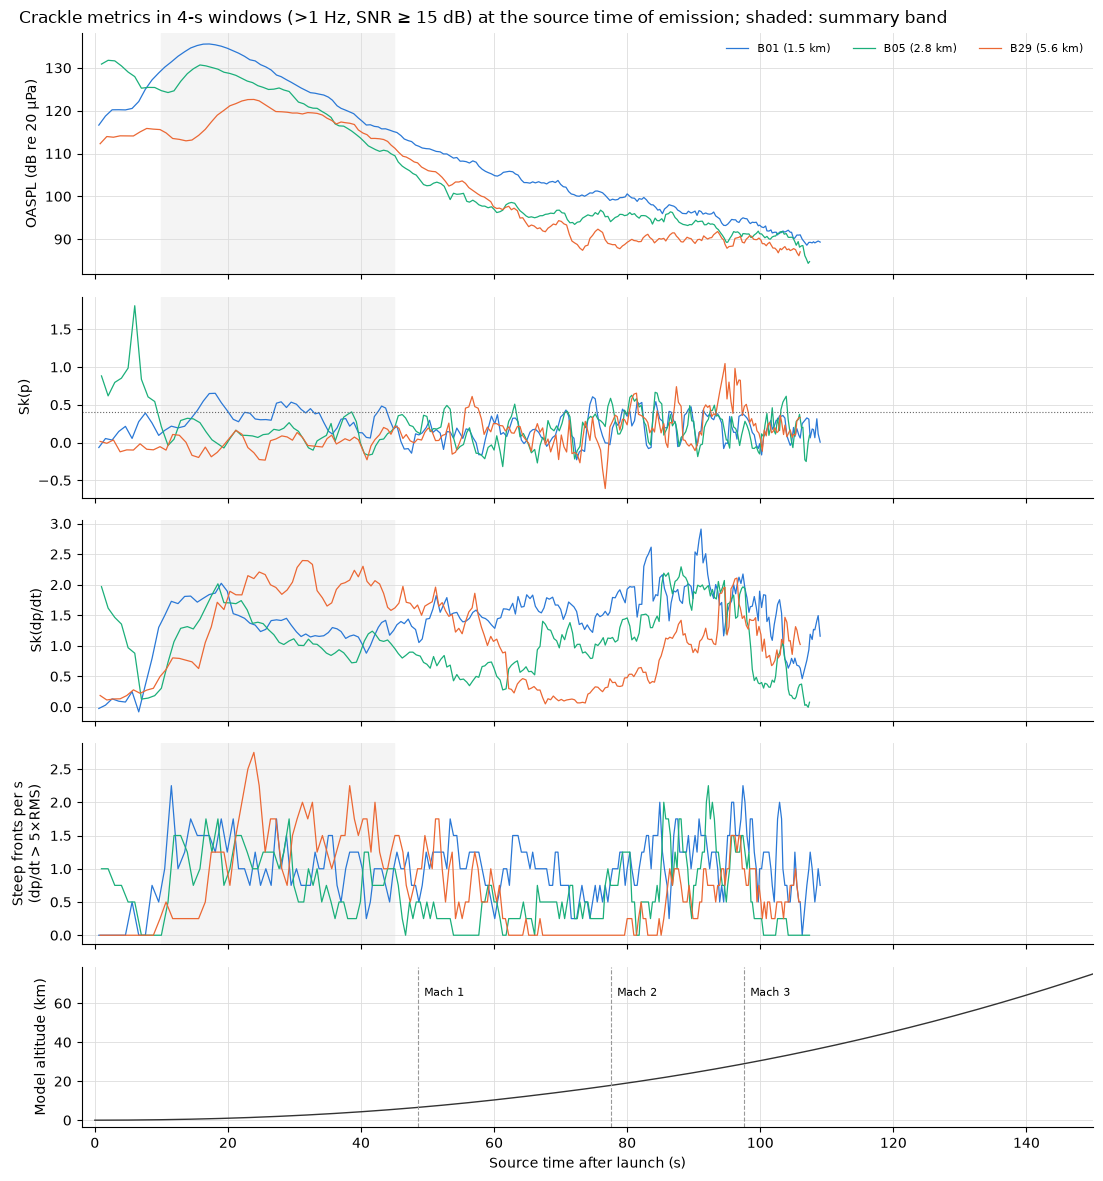

In [4]:
fig, ax = plt.subplots(5, 1, figsize=(11, 12), sharex=True,
                       gridspec_kw=dict(height_ratios=[1.2, 1, 1, 1, 0.8]))
for sta, g in cr[cr.valid].dropna(subset=['t_source']).groupby('station'):
    col = COLORS[sta]
    lab = f"{sta} ({stations.distance_km[sta]:.1f} km)"
    ax[0].plot(g.t_source, g.oaspl_db, color=col, lw=0.9, label=lab)
    ax[1].plot(g.t_source, g.sk_p, color=col, lw=0.9)
    ax[2].plot(g.t_source, g.sk_dpdt, color=col, lw=0.9)
    ax[3].plot(g.t_source, g.fronts_per_s, color=col, lw=0.9)
ax[0].set_ylabel('OASPL (dB re 20 µPa)')
ax[0].legend(frameon=False, fontsize=8, ncol=3)
ax[1].axhline(0.4, color='#666666', ls=':', lw=0.8)
ax[1].set_ylabel('Sk(p)')
ax[2].set_ylabel('Sk(dp/dt)')
ax[3].set_ylabel(f'Steep fronts per s\n(dp/dt > {FRONT_K:g}×RMS)')
geo = cfg.source_geometry('B29')
g = geo[geo.t_s <= 150]
ax[4].plot(g.t_s, g.alt_km, color='#333333', lw=1)
ax[4].set_ylabel('Model altitude (km)')
for m in (1, 2, 3):
    tm = g.t_s[g.mach >= m].min()
    ax[4].axvline(tm, color='#999999', ls='--', lw=0.8)
    ax[4].text(tm + 1, g.alt_km.max() * 0.85, f'Mach {m}', fontsize=8)
ax[4].set_xlabel('Source time after launch (s)')
ax[4].set_xlim(-2, 150)
for a in ax[:4]:
    a.axvspan(*BAND_TS, color='#f4f4f4', zorder=0)
fig.suptitle(f'Crackle metrics in {WIN:g}-s windows (>1 Hz, SNR ≥ {SNR_DB:g} dB) at the source time of emission; shaded: summary band', x=0.01, ha='left')
fig.tight_layout()
fig.savefig(OUT / 'crackle_vs_source_time.png', dpi=200)

## 4. Example waveforms

The most derivative-skewed window at each station, against a quiet late window.

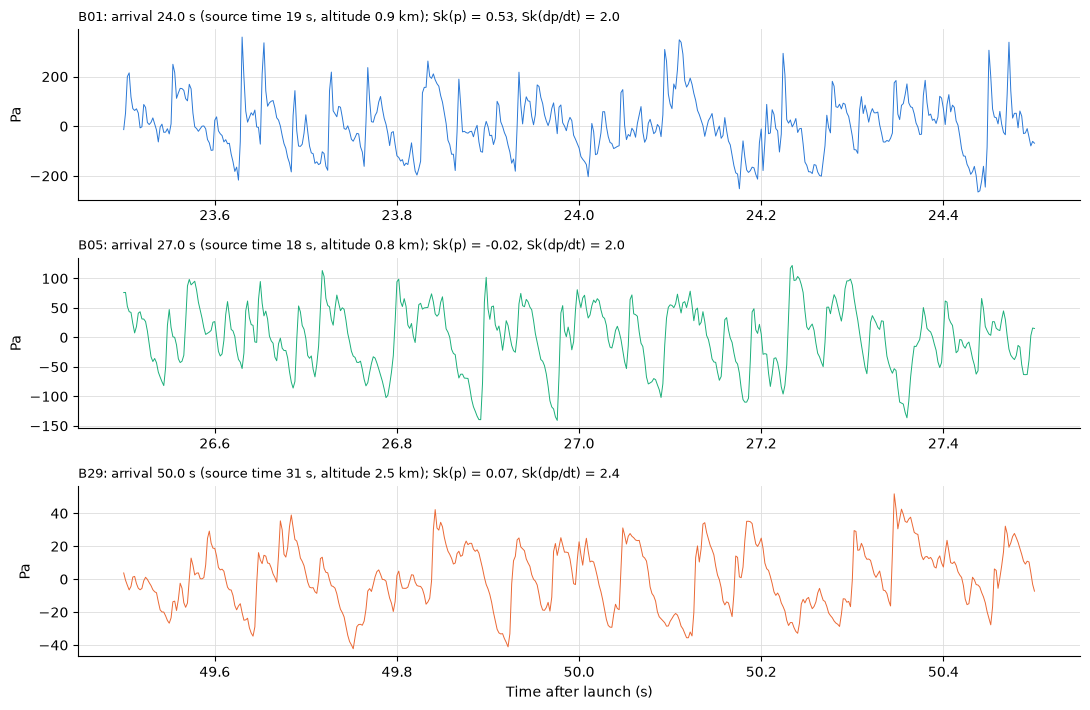

In [5]:
fig, ax = plt.subplots(len(st), 1, figsize=(11, 2.4 * len(st)), squeeze=False)
for a, tr in zip(ax[:, 0], st):
    sta = tr.stats.station
    g = cr[(cr.station == sta) & cr.valid & cr.t_source.between(*BAND_TS)]
    t_best = g.t_arrival[g.sk_dpdt.idxmax()]
    s = tr.slice(L + t_best - 0.5, L + t_best + 0.5)
    a.plot(s.times() + t_best - 0.5, s.data, color=COLORS[sta], lw=0.7)
    row = g.loc[g.sk_dpdt.idxmax()]
    a.set_title(f"{sta}: arrival {t_best:.1f} s (source time {row.t_source:.0f} s, altitude "
                f"{row.alt_km:.1f} km); Sk(p) = {row.sk_p:.2f}, Sk(dp/dt) = {row.sk_dpdt:.1f}",
                fontsize=9, loc='left')
    a.set_ylabel('Pa')
ax[-1, 0].set_xlabel('Time after launch (s)')
fig.tight_layout()
fig.savefig(OUT / 'crackle_waveforms.png', dpi=200)

## 5. What sampling rate does crackle need?

The loudest 60 s at each station, recomputed after decimation to 250, 200 and 100 sps
(scipy `resample_poly`, anti-alias filtered).

In [6]:
rows = []
for tr in st:
    sta = tr.stats.station
    g = cr[cr.station == sta]
    t_pk = g.t_arrival[g.oaspl_db.idxmax()]
    seg = tr.slice(L + t_pk - 30, L + t_pk + 30)
    for fs_new in (500, 250, 200, 100):
        x = seg.data.astype(float)
        if fs_new < 500:
            x = resample_poly(x, fs_new, 500)
        n = int(fs_new * 1.0)
        vals = [window_stats(x[i:i + n], fs_new) for i in range(0, len(x) - n, n)]
        rows.append(dict(station=sta, fs=fs_new,
                         median_sk_p=np.median([v['sk_p'] for v in vals]),
                         median_sk_dpdt=np.median([v['sk_dpdt'] for v in vals]),
                         max_sk_dpdt=np.max([v['sk_dpdt'] for v in vals]),
                         peak_Pa=np.abs(x).max()))
sr = pd.DataFrame(rows)
sr.to_csv(OUT / 'crackle_sampling_rate.csv', index=False)
with pd.option_context('display.float_format', '{:.2f}'.format):
    display(sr.pivot(index='fs', columns='station', values=['median_sk_dpdt', 'max_sk_dpdt', 'median_sk_p']))

median_sk_dpdt           max_sk_dpdt           median_sk_p           
station            B01  B05  B29         B01  B05  B29         B01  B05   B29
fs                                                                           
100               0.45 0.21 0.62        1.29 1.45 1.45        0.02 0.05 -0.08
200               0.94 0.16 1.24        1.89 1.74 2.33        0.14 0.06 -0.09
250               0.88 0.15 1.43        1.78 2.01 2.43        0.19 0.08 -0.08
500               1.12 0.16 1.65        2.35 2.13 2.73        0.27 0.13 -0.03

## Notes

* Source times use straight rays and the nominal trajectory; mapping uncertainties grow after ~60 s.
* Sk(p) is nearly independent of sampling rate; Sk(dp/dt) depends strongly on it because the shock
  rise time is not resolved, so derivative skewness values are only comparable at equal rates.
* The infraBSU response above ~100 Hz is nominal; skewness is insensitive to gain but not to phase.

## 6. Combined figure for the paper

(a) Excerpts with the largest derivative skewness at each station (source times 10–45 s); (b) crackle
metrics against source time, with the model altitude. Sized for full page width.
Output: `crackle_figure.png`.

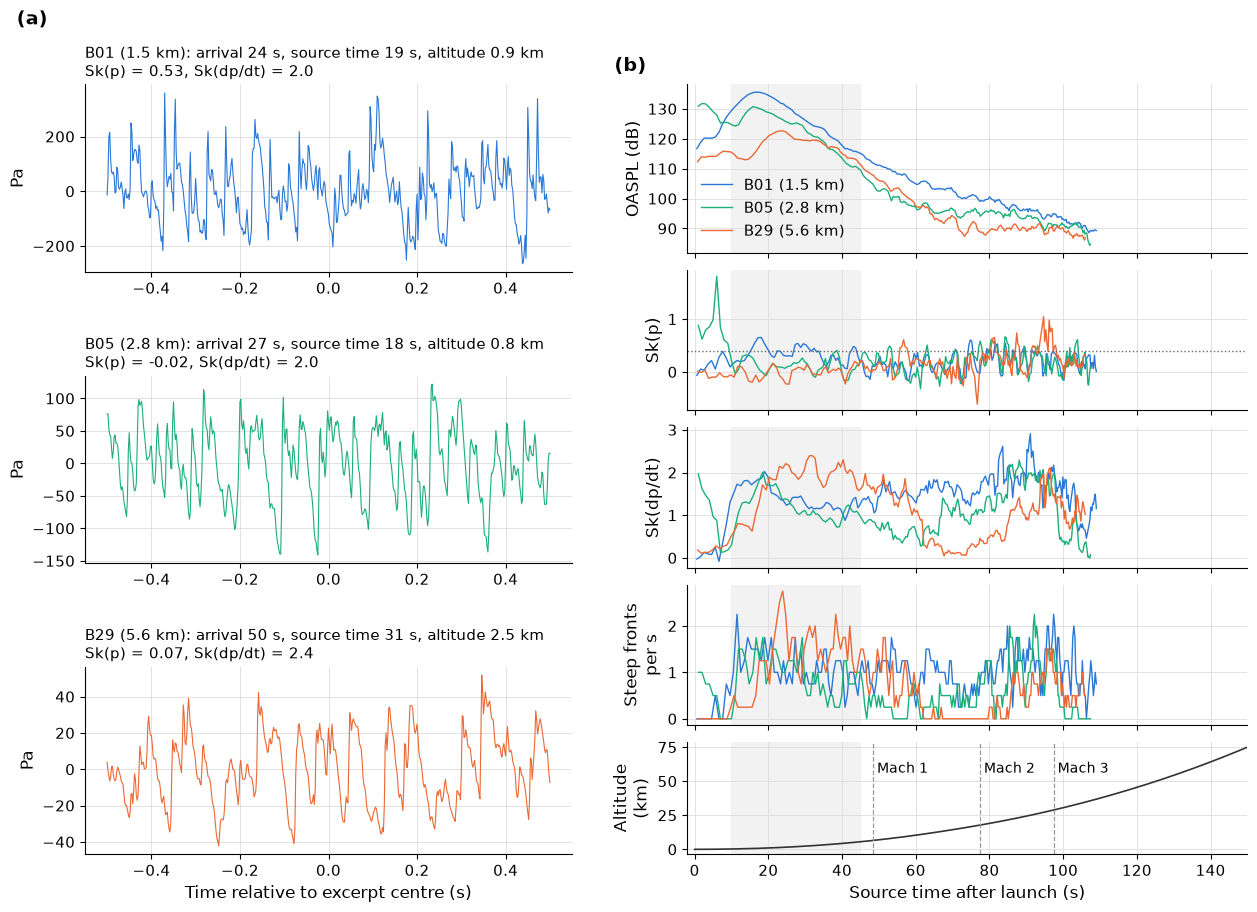

In [7]:
with plt.rc_context({'font.size': 12, 'axes.titlesize': 12, 'axes.labelsize': 12,
                     'xtick.labelsize': 11, 'ytick.labelsize': 11, 'legend.fontsize': 11}):
    fig = plt.figure(figsize=(15, 10))
    outer = fig.add_gridspec(1, 2, width_ratios=[1, 1.15], wspace=0.22)
    left = outer[0].subgridspec(len(st), 1, hspace=0.55)
    right = outer[1].subgridspec(5, 1, hspace=0.12, height_ratios=[1.2, 1, 1, 1, 0.8])
    for i, tr in enumerate(sorted(st, key=lambda t: stations.distance_km[t.stats.station])):
        sta = tr.stats.station
        g = cr[(cr.station == sta) & cr.valid & cr.t_source.between(*BAND_TS)]
        row = g.loc[g.sk_dpdt.idxmax()]
        t_best = row.t_arrival
        s = tr.slice(L + t_best - 0.5, L + t_best + 0.5)
        ax = fig.add_subplot(left[i])
        ax.plot(s.times() - 0.5, s.data, color=COLORS[sta], lw=0.8)
        ax.set_title(f"{sta} ({stations.distance_km[sta]:.1f} km): arrival {t_best:.0f} s, source time "
                     f"{row.t_source:.0f} s, altitude {row.alt_km:.1f} km\n"
                     f"Sk(p) = {row.sk_p:.2f}, Sk(dp/dt) = {row.sk_dpdt:.1f}", loc='left', fontsize=11)
        ax.set_ylabel('Pa')
        ax.grid(True, color='#dddddd', lw=0.6)
        if i == len(st) - 1:
            ax.set_xlabel('Time relative to excerpt centre (s)')
        if i == 0:
            ax.text(-0.14, 1.32, '(a)', transform=ax.transAxes, fontsize=14, fontweight='bold')
    axr = [fig.add_subplot(right[j]) for j in range(5)]
    for a in axr[1:]:
        a.sharex(axr[0])
    for sta, g in cr[cr.valid].dropna(subset=['t_source']).groupby('station'):
        col = COLORS[sta]
        axr[0].plot(g.t_source, g.oaspl_db, color=col, lw=1, label=f"{sta} ({stations.distance_km[sta]:.1f} km)")
        axr[1].plot(g.t_source, g.sk_p, color=col, lw=1)
        axr[2].plot(g.t_source, g.sk_dpdt, color=col, lw=1)
        axr[3].plot(g.t_source, g.fronts_per_s, color=col, lw=1)
    axr[0].set_ylabel('OASPL (dB)')
    axr[0].legend(frameon=False, ncol=1, loc='lower left')
    axr[1].axhline(0.4, color='#666666', ls=':', lw=1)
    axr[1].set_ylabel('Sk(p)')
    axr[2].set_ylabel('Sk(dp/dt)')
    axr[3].set_ylabel('Steep fronts\nper s')
    geo = cfg.source_geometry('B29')
    gg = geo[geo.t_s <= 150]
    axr[4].plot(gg.t_s, gg.alt_km, color='#333333', lw=1.2)
    for m in (1, 2, 3):
        tm = gg.t_s[gg.mach >= m].min()
        axr[4].axvline(tm, color='#999999', ls='--', lw=0.9)
        axr[4].text(tm + 1, gg.alt_km.max() * 0.75, f'Mach {m}', fontsize=10)
    axr[4].set_ylabel('Altitude\n(km)')
    axr[4].set_xlabel('Source time after launch (s)')
    axr[4].set_xlim(-2, 150)
    for a in axr:
        a.axvspan(*BAND_TS, color='#f2f2f2', zorder=0)
        a.grid(True, color='#dddddd', lw=0.6)
    for a in axr[:4]:
        a.tick_params(labelbottom=False)
    axr[0].text(-0.13, 1.08, '(b)', transform=axr[0].transAxes, fontsize=14, fontweight='bold')
    fig.savefig(OUT / 'crackle_figure.png', dpi=200, bbox_inches='tight')